<a href="https://colab.research.google.com/github/YaraAlamoudi/Image-Clustering--K-Means-and-Spectral-Clustering/blob/main/Lab1_2_KMeans_Spectral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from skimage import data

X, _ = make_blobs(n_samples=1000, centers=4, random_state=42)
print("Dataset shape:", X.shape)

Dataset shape: (1000, 2)


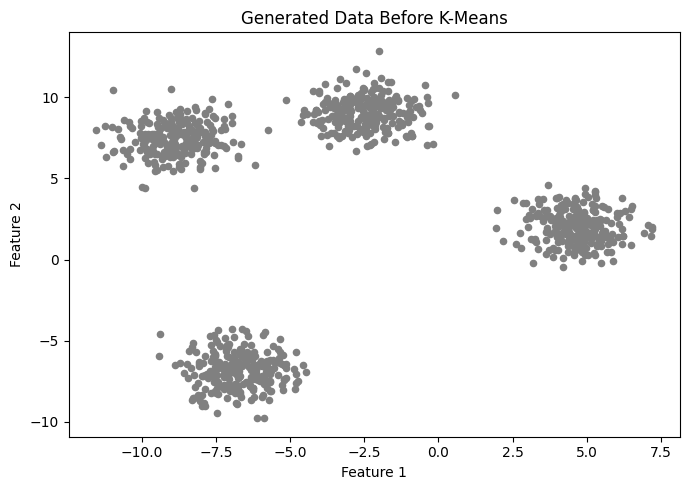

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], color="gray", s=20)
plt.title("Generated Data Before K-Means")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.savefig("kmeans_data_before.png", dpi=150)
plt.show()

In [5]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)
print("Number of points clustered:", len(kmeans_labels))
print("Cluster centers:\n", kmeans.cluster_centers_)

Number of points clustered: 1000
Cluster centers:
 [[-2.50173875  9.03287546]
 [-6.74543497 -6.81351756]
 [ 4.65760511  2.0269603 ]
 [-8.85662684  7.41339818]]


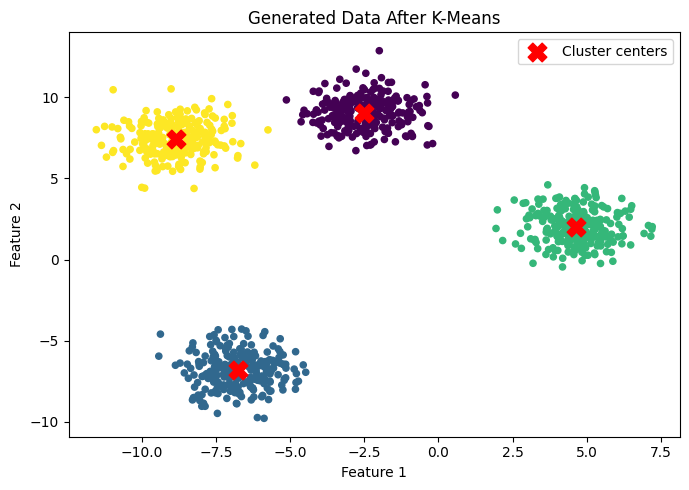

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=20)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", marker="X", s=180, label="Cluster centers")
plt.title("Generated Data After K-Means")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.savefig("kmeans_data_after.png", dpi=150)
plt.show()

In [7]:
coffee = data.coffee()
print("Coffee image shape:", coffee.shape)

Coffee image shape: (400, 600, 3)


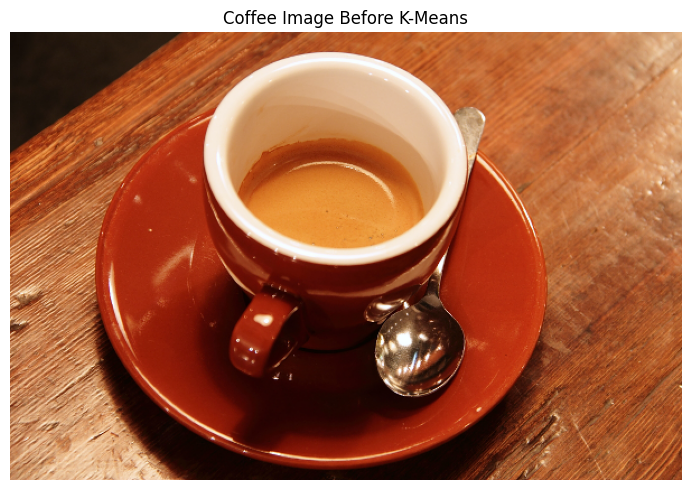

In [8]:
plt.figure(figsize=(8, 5))
plt.imshow(coffee)
plt.title("Coffee Image Before K-Means")
plt.axis("off")
plt.tight_layout()
plt.savefig("kmeans_image_before.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
pixels = coffee.reshape(-1, 3)
image_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
pixel_labels = image_kmeans.fit_predict(pixels)
segmented_coffee = image_kmeans.cluster_centers_[pixel_labels].reshape(coffee.shape)
segmented_coffee = np.clip(segmented_coffee, 0, 255).astype(np.uint8)
print("Pixel array shape:", pixels.shape)
print("Segmented image shape:", segmented_coffee.shape)

Pixel array shape: (240000, 3)
Segmented image shape: (400, 600, 3)


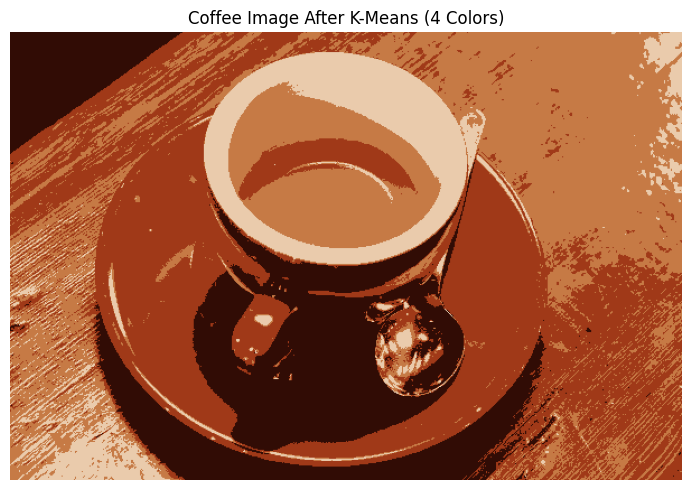

In [10]:
plt.figure(figsize=(8, 5))
plt.imshow(segmented_coffee)
plt.title("Coffee Image After K-Means (4 Colors)")
plt.axis("off")
plt.tight_layout()
plt.savefig("kmeans_image_after.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
from sklearn.datasets import make_circles
from sklearn.cluster import SpectralClustering, spectral_clustering
from sklearn.feature_extraction import image as sk_image
from skimage.transform import rescale
from skimage.filters import gaussian

circles, _ = make_circles(n_samples=1000, factor=0.5, noise=0.05, random_state=42)
print("Dataset shape:", circles.shape)

Dataset shape: (1000, 2)


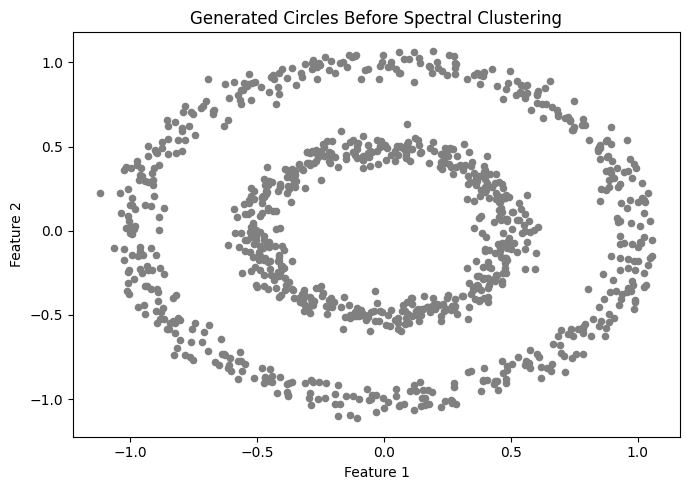

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(circles[:, 0], circles[:, 1], color="gray", s=20)
plt.title("Generated Circles Before Spectral Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.savefig("spectral_data_before.png", dpi=150)
plt.show()

In [13]:
spectral_model = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", random_state=42
)
spectral_labels = spectral_model.fit_predict(circles)
print("Number of points clustered:", len(spectral_labels))
print("Cluster labels:", np.unique(spectral_labels))

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Number of points clustered: 1000
Cluster labels: [0 1]


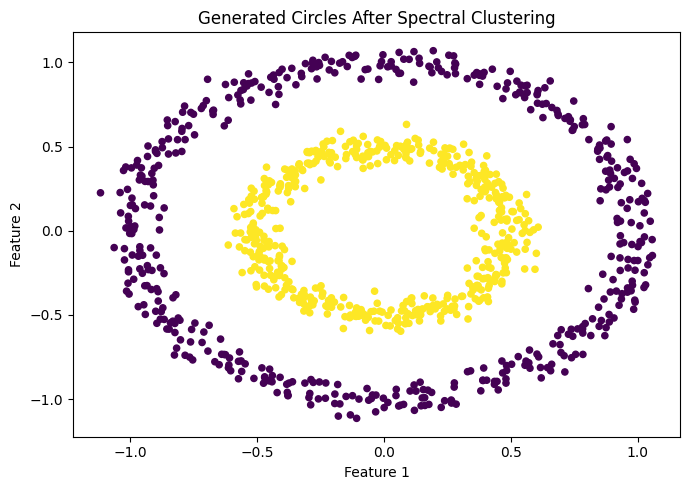

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(circles[:, 0], circles[:, 1], c=spectral_labels, cmap="viridis", s=20)
plt.title("Generated Circles After Spectral Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.savefig("spectral_data_after.png", dpi=150)
plt.show()

In [15]:
coins = data.coins()
print("Coins image shape:", coins.shape)

Coins image shape: (303, 384)


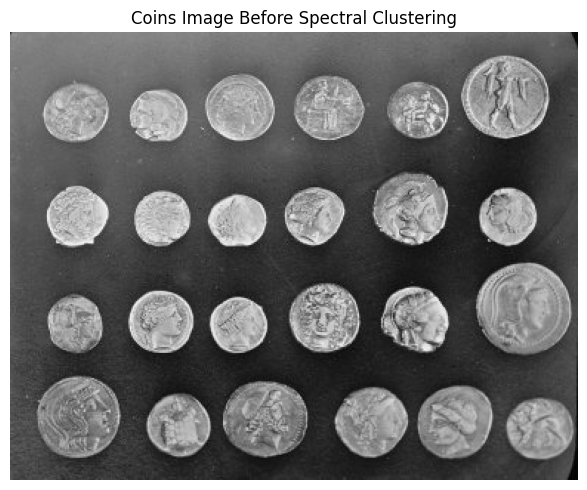

In [16]:
plt.figure(figsize=(8, 5))
plt.imshow(coins, cmap="gray")
plt.title("Coins Image Before Spectral Clustering")
plt.axis("off")
plt.tight_layout()
plt.savefig("spectral_image_before.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
smoothed = gaussian(coins, sigma=2)
small_image = rescale(smoothed, 0.2, anti_aliasing=False)
graph = sk_image.img_to_graph(small_image)
graph.data = np.exp(-10 * graph.data / graph.data.std())

coin_labels = spectral_clustering(
    graph, n_clusters=25, assign_labels="discretize", random_state=42
)
coin_labels = coin_labels.reshape(small_image.shape)
print("Smaller image shape:", small_image.shape)
print("Number of regions:", len(np.unique(coin_labels)))

Smaller image shape: (61, 77)
Number of regions: 25


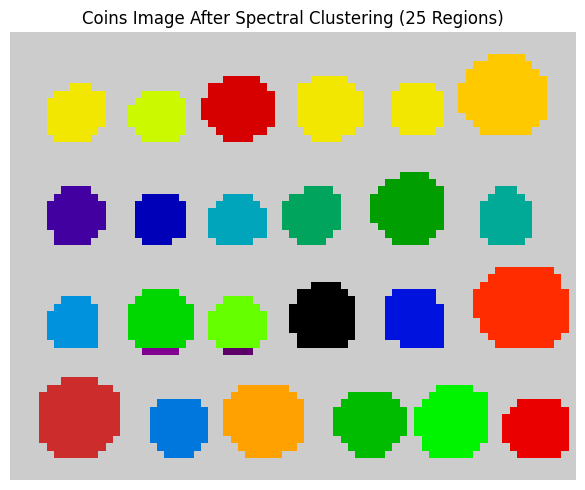

In [18]:
plt.figure(figsize=(8, 5))
plt.imshow(coin_labels, cmap="nipy_spectral")
plt.title("Coins Image After Spectral Clustering (25 Regions)")
plt.axis("off")
plt.tight_layout()
plt.savefig("spectral_image_after.png", dpi=150, bbox_inches="tight")
plt.show()